In [1]:
%pip install pandas numpy matplotlib seaborn nltk textblob scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report, accuracy_score

nltk.download('stopwords')
nltk.download('wordnet')

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\USER\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\USER\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


True

In [3]:
df = pd.read_csv(r"C:\Users\USER\Downloads\3) Sentiment dataset.csv")
df.head()

,Unnamed: 0.1,Unnamed: 0,Text,Sentiment,Timestamp,User,Platform,Hashtags,Retweets,Likes,Country,Year,Month,Day,Hour
0,0,0,Enjoying a beautiful day at the park! ...,Positive,2023-01-15 12:30:00,User123,Twitter,#Nature #Park,15.0,30.0,USA,2023,1,15,12
1,1,1,Traffic was terrible this morning. ...,Negative,2023-01-15 08:45:00,CommuterX,Twitter,#Traffic #Morning,5.0,10.0,Canada,2023,1,15,8
2,2,2,Just finished an amazing workout! 💪 ...,Positive,2023-01-15 15:45:00,FitnessFan,Instagram,#Fitness #Workout,20.0,40.0,USA,2023,1,15,15
3,3,3,Excited about the upcoming weekend getaway! ...,Positive,2023-01-15 18:20:00,AdventureX,Facebook,#Travel #Adventure,8.0,15.0,UK,2023,1,15,18
4,4,4,Trying out a new recipe for dinner tonight. ...,Neutral,2023-01-15 19:55:00,ChefCook,Instagram,#Cooking #Food,12.0,25.0,Australia,2023,1,15,19


In [4]:
# 1. Drop the extra 'Unnamed' index columns if they exist
df = df.drop(columns=['Unnamed: 0.1', 'Unnamed: 0'], errors='ignore')

# 2. Remove any extra whitespace from Text and Sentiment
df['Text'] = df['Text'].astype(str).str.strip()
df['Sentiment'] = df['Sentiment'].astype(str).str.strip()

# 3. Clean text: lowercase, remove punctuation/numbers, remove stopwords, and lemmatize
stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def clean_text(text):
    text = text.lower()
    text = re.sub(r'[^a-z\s]', '', text)
    words = text.split()
    words = [lemmatizer.lemmatize(w) for w in words if w not in stop_words]
    return ' '.join(words)

df['Cleaned_Text'] = df['Text'].apply(clean_text)

# Preview the before and after
print("Total rows:", len(df))
print("\nUnique Sentiment Labels:", df['Sentiment'].nunique())
print(df[['Text', 'Cleaned_Text', 'Sentiment']].head())

Total rows: 732

Unique Sentiment Labels: 191
                                          Text  \
0        Enjoying a beautiful day at the park!   
1           Traffic was terrible this morning.   
2          Just finished an amazing workout! 💪   
3  Excited about the upcoming weekend getaway!   
4  Trying out a new recipe for dinner tonight.   

                       Cleaned_Text Sentiment  
0       enjoying beautiful day park  Positive  
1          traffic terrible morning  Negative  
2          finished amazing workout  Positive  
3  excited upcoming weekend getaway  Positive  
4  trying new recipe dinner tonight   Neutral  


In [5]:
print("Top 20 Sentiment Labels")
print(df['Sentiment'].value_counts().head(20))

Top 20 Sentiment Labels
Sentiment
Positive       45
Joy            44
Excitement     37
Contentment    19
Neutral        18
Gratitude      18
Curiosity      16
Serenity       15
Happy          14
Despair        11
Nostalgia      11
Awe             9
Grief           9
Loneliness      9
Hopeful         9
Sad             9
Acceptance      8
Confusion       8
Embarrassed     8
Pride           7
Name: count, dtype: int64


In [6]:
counts = df['Sentiment'].value_counts()
print("\nLabels with 10 or more examples:", len(counts[counts >=10]))


Labels with 10 or more examples: 11


In [7]:
from sklearn.linear_model import LogisticRegression

valid_sentiments = counts[counts >= 10].index
df_filtered = df[df['Sentiment'].isin(valid_sentiments)]

x= df_filtered['Cleaned_Text']
y= df_filtered['Sentiment']

In [8]:
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42, stratify=y
)

In [9]:
tfidf = TfidfVectorizer(max_features=3000)
x_train_tfidf = tfidf.fit_transform(x_train)
x_test_tfidf = tfidf.transform(x_test)

In [10]:
model = LogisticRegression(max_iter=1000)
model.fit(x_train_tfidf, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [11]:
y_pred = model.predict(x_test_tfidf)
print("Model Accuracy:", round(accuracy_score(y_test, y_pred) * 100,2), "%")
print("\nClassification Report:\n", classification_report(y_test, y_pred, zero_division=0))


Model Accuracy: 42.0 %

Classification Report:
               precision    recall  f1-score   support

 Contentment       1.00      0.25      0.40         4
   Curiosity       1.00      0.67      0.80         3
     Despair       1.00      0.50      0.67         2
  Excitement       0.33      0.14      0.20         7
   Gratitude       1.00      0.25      0.40         4
       Happy       0.00      0.00      0.00         3
         Joy       0.29      0.56      0.38         9
     Neutral       0.00      0.00      0.00         4
   Nostalgia       1.00      1.00      1.00         2
    Positive       0.29      0.67      0.40         9
    Serenity       1.00      0.67      0.80         3

    accuracy                           0.42        50
   macro avg       0.63      0.43      0.46        50
weighted avg       0.51      0.42      0.40        50



In [12]:
from collections import Counter

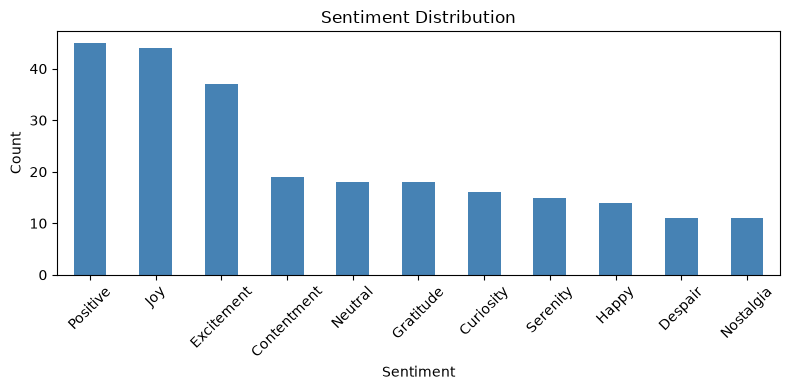

In [13]:
plt.figure(figsize=(8, 4))
df_filtered['Sentiment'].value_counts().plot(kind='bar', color='steelblue')
plt.title('Sentiment Distribution')
plt.xlabel('Sentiment')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.tight_layout()


C:\Users\USER\AppData\Local\Temp\ipykernel_4840\3046911166.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=words_df, x='Frequency', y='Word', palette='viridis')


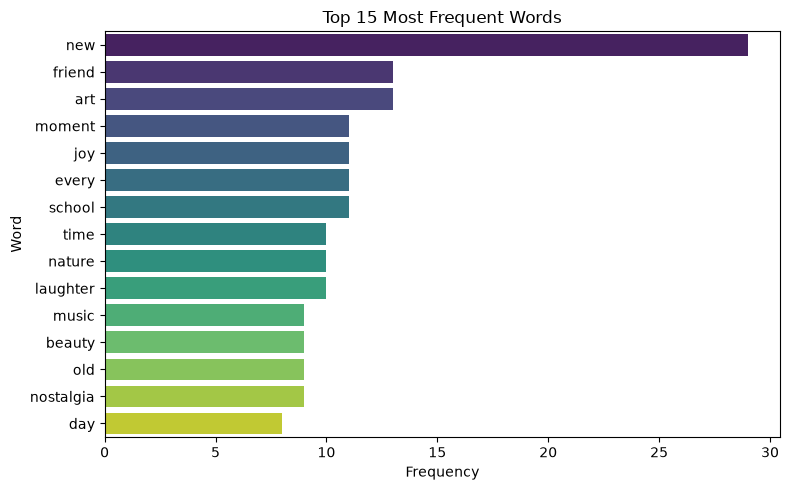

In [14]:
all_words = ''.join(df_filtered['Cleaned_Text']).split()
words_df = pd.DataFrame(Counter(all_words).most_common(15), columns=['Word', 'Frequency'])

plt.figure(figsize=(8, 5))
sns.barplot(data=words_df, x='Frequency', y='Word', palette='viridis')
plt.title('Top 15 Most Frequent Words')
plt.tight_layout()
plt.show()